# 09 – Đánh giá chuyên sâu, chi phí kinh doanh, XAI, đạo đức AI (P5 + P1.4)

⚠️ **Chạy lại toàn bộ notebook này sau khi gán xong tập vàng.** Khi chưa đủ 50 câu nhãn tay, notebook TẠM dùng nhãn sao của kho vàng. Lúc đó:
- mọi con số chỉ để thử code;
- riêng phân tích chi phí "lọc theo sao" sẽ **đúng tuyệt đối một cách giả tạo**, vì nhãn chính là sao.

Nội dung:
1. Chỉ số đầy đủ: Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC, khoảng tin cậy bootstrap.
2. Ma trận nhầm lẫn và **chi phí kinh doanh** → ROI (đưa lên P1.4).
3. Human-in-the-loop: chuyển câu không chắc chắn cho người.
4. Fairness: theo ngành hàng, theo văn bản không dấu.
5. XAI: giá trị SHAP của mô hình tuyến tính (toàn cục và từng câu).
6. Xuất câu sai để phân tích lỗi.

In [1]:
import sys, os, joblib
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (f1_score, accuracy_score, precision_score, recall_score, roc_auc_score,
                             average_precision_score, confusion_matrix, classification_report,
                             precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.preprocessing import label_binarize
from src.data import load_sets, load_gold, LABELS

FIG, REP, MOD = "../figures", "../report", "../models"
rng = np.random.default_rng(42)
gold, GOLD_TEMP = load_gold()
TAG = "TẠM – nhãn sao" if GOLD_TEMP else "nhãn tay"
print(f"Tập vàng ({TAG}): {len(gold)} câu", gold.label.value_counts().to_dict())
A_test = load_sets()["A_test"]
Xg, Xt = gold[["text_prep", "text_raw"]], A_test[["text_prep", "text_raw"]]

Tập vàng (nhãn tay): 300 câu {'pos': 148, 'neg': 121, 'neu': 31}


## 1. Nạp mô hình và tính xác suất

- LinearSVC không có xác suất. Dùng `decision_function` làm điểm số để tính AUC; AUC chỉ cần thứ tự điểm, không cần xác suất.
- PhoBERT: đọc kết quả từ Colab (`report/phobert/`) nếu đã có.

In [2]:
def softmax(z):
    z = z - z.max(1, keepdims=True)
    return np.exp(z) / np.exp(z).sum(1, keepdims=True)

models = {"BoW+NB (baseline)": "bow_nb_AB", "TF-IDF+LR": "tfidf_lr_AB",
          "TF-IDF+LinearSVC": "tfidf_svc_AB", "TF-IDF+đặc trưng+LR": "tfidf_feat_lr_AB"}
scores, scores_test, fitted = {}, {}, {}
for name, fn in models.items():
    m = joblib.load(f"{MOD}/{fn}.joblib")
    fitted[name] = m
    f = m.predict_proba if hasattr(m, "predict_proba") else (lambda X, m=m: softmax(m.decision_function(X)))
    scores[name], scores_test[name] = f(Xg), f(Xt)

PB = "../report/phobert"
if os.path.exists(f"{PB}/phobert_gold_pool_proba.csv"):
    pb = pd.read_csv(f"{PB}/phobert_gold_pool_proba.csv").set_index("id")
    scores["PhoBERT"] = pb.loc[gold.id, ["p_neg", "p_neu", "p_pos"]].values
    scores_test["PhoBERT"] = pd.read_csv(f"{PB}/phobert_visd_test_proba.csv")[["p_neg", "p_neu", "p_pos"]].values
    print("Đã nạp PhoBERT")
else:
    print("Chưa có kết quả PhoBERT (chạy notebook 08 trên Colab).")

Đã nạp PhoBERT


## 2. Bảng chỉ số chính

**Chỉ số nghiệp vụ chính là Recall tiêu cực, luôn báo kèm F1-macro.** Accuracy chỉ tham khảo khi lớp lệch. Điểm vàng là thăm dò; chọn mô hình có điểm vàng cao nhất bên dưới chỉ phục vụ hậu kiểm, không chọn mô hình triển khai.

In [3]:
Y = label_binarize(gold.label, classes=LABELS)
rows = []
for name, P in scores.items():
    pred = np.array(LABELS)[P.argmax(1)]
    rows.append({"Mô hình": name,
                 "Accuracy": accuracy_score(gold.label, pred),
                 "Precision (macro)": precision_score(gold.label, pred, average="macro", zero_division=0),
                 "Recall (macro)": recall_score(gold.label, pred, average="macro"),
                 "F1-macro": f1_score(gold.label, pred, average="macro"),
                 "Recall neg": recall_score(gold.label, pred, labels=["neg"], average="macro"),
                 "ROC-AUC (OvR)": roc_auc_score(Y, P, average="macro"),
                 "PR-AUC (macro)": average_precision_score(Y, P, average="macro"),
                 "F1 ViSD test": f1_score(A_test.label, np.array(LABELS)[scores_test[name].argmax(1)], average="macro")})
main = pd.DataFrame(rows).set_index("Mô hình").round(3)
main.to_csv(f"{REP}/main_results.csv", encoding="utf-8-sig")
BEST = main["F1-macro"].idxmax()
# LinearSVC không có xác suất thật (softmax của decision_function không hiệu chỉnh), nên các phân tích
# cần ngưỡng xác suất (chi phí, Human-in-the-loop, câu sai) dùng mô hình xác suất tốt nhất.
BEST_P = main.drop(index="TF-IDF+LinearSVC")["F1-macro"].idxmax()
print("Mô hình xác suất tốt nhất (dùng cho chi phí, HITL):", BEST_P)
print("Mô hình tốt nhất theo F1-macro trên tập vàng:", BEST)
main

Mô hình xác suất tốt nhất (dùng cho chi phí, HITL): PhoBERT
Mô hình tốt nhất theo F1-macro trên tập vàng: PhoBERT


,Accuracy,Precision (macro),Recall (macro),F1-macro,Recall neg,ROC-AUC (OvR),PR-AUC (macro),F1 ViSD test
Mô hình,,,,,,,,
BoW+NB (baseline),0.803,0.875,0.601,0.583,0.810,0.836,0.670,0.585
TF-IDF+LR,0.810,0.766,0.615,0.605,0.826,0.863,0.710,0.724
TF-IDF+LinearSVC,0.803,0.763,0.609,0.601,0.810,0.860,0.702,0.699
TF-IDF+đặc trưng+LR,0.823,0.775,0.642,0.646,0.851,0.861,0.714,0.719
PhoBERT,0.837,0.726,0.694,0.704,0.851,0.902,0.761,0.779


In [4]:
print(f"Báo cáo từng lớp – {BEST} ({TAG})")
print(classification_report(gold.label, np.array(LABELS)[scores[BEST].argmax(1)], digits=3))

Báo cáo từng lớp – PhoBERT (nhãn tay)
              precision    recall  f1-score   support

         neg      0.866     0.851     0.858       121
         neu      0.450     0.290     0.353        31
         pos      0.863     0.939     0.900       148

    accuracy                          0.837       300
   macro avg      0.726     0.694     0.704       300
weighted avg      0.822     0.837     0.827       300



### Khoảng tin cậy bootstrap 95%

Tập vàng nhỏ nên F1 dao động. Lấy mẫu lại có hoàn lại 1.000 lần. Hai mô hình có khoảng tin cậy chồng nhau nhiều thì **chưa đủ bằng chứng** để nói mô hình nào tốt hơn.

In [5]:
def boot_f1(y, pred, n=1000):
    y, pred = np.asarray(y), np.asarray(pred)
    idx = rng.integers(0, len(y), (n, len(y)))
    return np.array([f1_score(y[i], pred[i], average="macro") for i in idx])

ci, boots = [], {}
for name, P in scores.items():
    b = boot_f1(gold.label, np.array(LABELS)[P.argmax(1)])
    boots[name] = b
    ci.append({"Mô hình": name, "F1-macro": main.loc[name, "F1-macro"],
               "CI 2.5%": np.percentile(b, 2.5), "CI 97.5%": np.percentile(b, 97.5)})
ci = pd.DataFrame(ci).set_index("Mô hình").round(3)
ci.to_csv(f"{REP}/bootstrap_ci.csv", encoding="utf-8-sig")
ci

,F1-macro,CI 2.5%,CI 97.5%
Mô hình,,,
BoW+NB (baseline),0.583,0.537,0.633
TF-IDF+LR,0.605,0.555,0.670
TF-IDF+LinearSVC,0.601,0.546,0.661
TF-IDF+đặc trưng+LR,0.646,0.580,0.710
PhoBERT,0.704,0.640,0.767


In [6]:
# Bootstrap ghép cặp: mô hình tốt nhất hơn baseline bao nhiêu, có chắc không?
y = gold.label.values
pb_, pbase = np.array(LABELS)[scores[BEST].argmax(1)], np.array(LABELS)[scores["BoW+NB (baseline)"].argmax(1)]
idx = rng.integers(0, len(y), (1000, len(y)))
diff = np.array([f1_score(y[i], pb_[i], average="macro") - f1_score(y[i], pbase[i], average="macro") for i in idx])
print(f"{BEST} − baseline: {diff.mean():+.3f}, CI95 [{np.percentile(diff, 2.5):+.3f}, {np.percentile(diff, 97.5):+.3f}],"
      f" P(chênh > 0) = {(diff > 0).mean():.2f}")

PhoBERT − baseline: +0.119, CI95 [+0.044, +0.190], P(chênh > 0) = 1.00


### Đường Precision–Recall và ma trận nhầm lẫn

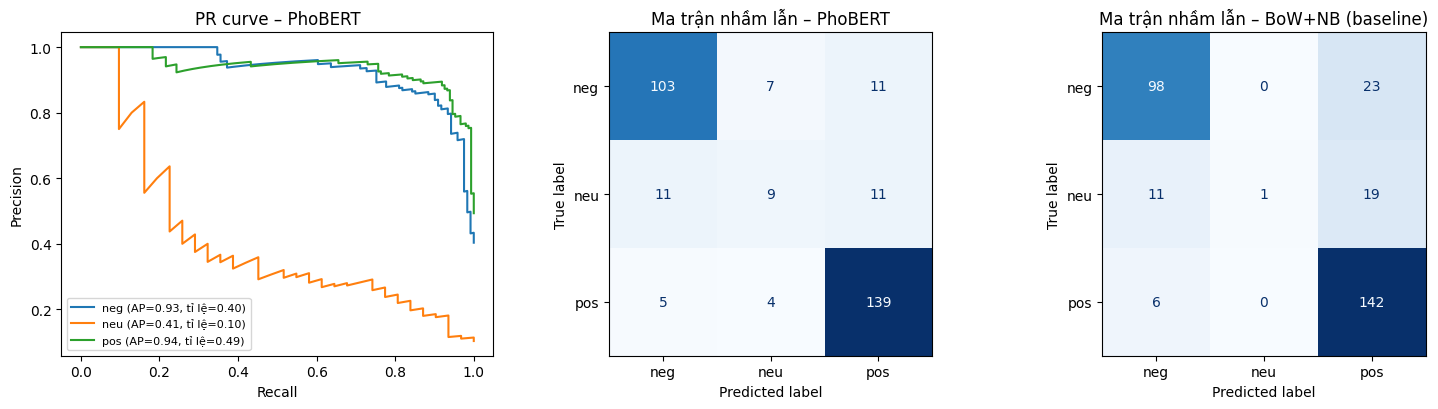

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
P = scores[BEST]
for k, lab in enumerate(LABELS):
    pr, rc, _ = precision_recall_curve(Y[:, k], P[:, k])
    ax[0].plot(rc, pr, label=f"{lab} (AP={average_precision_score(Y[:, k], P[:, k]):.2f}, tỉ lệ={Y[:, k].mean():.2f})")
ax[0].set(xlabel="Recall", ylabel="Precision", title=f"PR curve – {BEST}"); ax[0].legend(fontsize=8)
for a, name in zip(ax[1:], [BEST, "BoW+NB (baseline)"]):
    ConfusionMatrixDisplay.from_predictions(gold.label, np.array(LABELS)[scores[name].argmax(1)], labels=LABELS,
                                            ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"Ma trận nhầm lẫn – {name}")
plt.tight_layout(); plt.savefig(f"{FIG}/eval_pr_cm.png", bbox_inches="tight"); plt.show()

**Đọc PR curve:** đường nằm ngang ở mức "tỉ lệ" là mô hình đoán bừa. PR-AUC của lớp neu thường thấp nhất vì lớp này hiếm và khó định nghĩa.

## 3. Chi phí kinh doanh của ma trận nhầm lẫn và ROI

**Bài toán của chủ shop:** mỗi tháng có N review. Review **tiêu cực** cần được đọc và phản hồi (xin lỗi, đổi trả, voucher) để giữ khách.

| Chiến lược | Đọc những review nào |
|---|---|
| (a) Đọc tay toàn bộ | tất cả |
| (b) **Lọc theo sao** (cách làm phổ biến hiện nay) | review 1–2 sao |
| (b2) Lọc rộng hơn | review 1–3 sao |
| (c) Mô hình | review mô hình dự đoán neg |
| (d) **Ghép sao và mô hình** | review ≤ 3 sao, cộng các review 4–5 sao mà mô hình không đoán pos |

- **Sai loại 1 (FP)**: đọc một review không tiêu cực, tốn `C_READ`.
- **Sai loại 2 (FN)**: bỏ sót một review tiêu cực, tốn `C_MISS` (khách không được xử lý, có thể bỏ shop, đánh giá xấu lan truyền).

**Hiệu chỉnh tỉ lệ sao:** tập vàng lấy dư review 1–3 sao, nên tỉ lệ review chê trong mẫu cao hơn thực tế. Muốn phóng lên N review/tháng phải gán trọng số cho mỗi câu, bằng tỉ lệ mức sao đó trên toàn bộ 2.548 review chia cho tỉ lệ của nó trong tập vàng. Vì vậy `Recall neg` ở bảng chi phí khác bảng chỉ số chính (bảng chính chấm trên đúng mẫu, không gán trọng số).

**Chiến lược (d) là phân tích thăm dò:** nó được đặt ra sau khi đã xem kết quả trên tập vàng, nên chưa được kiểm chứng độc lập. Cần ghi rõ điều này trong báo cáo.

⚠️ **Mọi con số dưới đây là GIẢ ĐỊNH.** Sửa cho phù hợp và ghi rõ trong báo cáo.

In [8]:
ASSUME = {
    "N_review_thang": 3000,        # review mỗi tháng (shop vừa, nhiều sản phẩm)
    "C_READ": 1_000,               # đọc + phân loại 1 review ≈ 30 giây × lương CSKH 120.000đ/giờ
    "C_MISS": 50_000,              # kỳ vọng thiệt hại khi bỏ sót 1 review chê ≈ 20% khả năng mất khách × 250.000đ lợi nhuận/khách
    "CHI_PHI_TRIEN_KHAI": 15_000_000,   # một lần: tích hợp, kiểm thử
    "CHI_PHI_VAN_HANH_THANG": 500_000,  # máy chủ nhỏ + bảo trì
}
pd.Series(ASSUME, name="Giả định")

N_review_thang                3000
C_READ                        1000
C_MISS                       50000
CHI_PHI_TRIEN_KHAI        15000000
CHI_PHI_VAN_HANH_THANG      500000
Name: Giả định, dtype: int64

In [9]:
is_neg = (gold.label == "neg").values

# Trọng số đưa tỉ lệ sao của tập vàng về tỉ lệ sao thật trên toàn bộ review Shopee
star_all = pd.read_csv("../data/processed/shopee_clean_all.csv").rating.value_counts(normalize=True)
w = gold.rating.map(star_all / gold.rating.value_counts(normalize=True)).values
w = w / w.sum()
print(f"Tỉ lệ review chê: trong mẫu {is_neg.mean():.1%}, sau hiệu chỉnh {w[is_neg].sum():.1%}")

def strategy_cost(flag, a=ASSUME):
    """flag: mảng bool, review nào được đọc. Trả về chi phí/tháng phóng theo N, có trọng số sao."""
    read = w[flag].sum() * a["N_review_thang"]
    fn = w[is_neg & ~flag].sum() * a["N_review_thang"]
    return {"Số review phải đọc/tháng": read,
            "Bỏ sót review chê/tháng": fn,
            "Recall neg": w[is_neg & flag].sum() / max(w[is_neg].sum(), 1e-9),
            "Chi phí đọc": read * a["C_READ"],
            "Chi phí bỏ sót": fn * a["C_MISS"]}

SAO_12, SAO_13 = "(b) Lọc theo sao (1–2 sao)", "(b2) Lọc theo sao (1–3 sao)"
DOC_HET = "(a) Đọc tay toàn bộ"
GHEP = f"(d) ≤ 3 sao hoặc {BEST_P} không đoán pos"
strategies = {DOC_HET: np.ones(len(gold), bool),
              SAO_12: (gold.rating <= 2).values,
              SAO_13: (gold.rating <= 3).values}
for name in scores:
    strategies[f"(c) {name}"] = np.array(LABELS)[scores[name].argmax(1)] == "neg"
strategies[GHEP] = (gold.rating <= 3).values | (np.array(LABELS)[scores[BEST_P].argmax(1)] != "pos")
cost = pd.DataFrame({k: strategy_cost(v) for k, v in strategies.items()}).T
cost["Tổng chi phí/tháng"] = cost["Chi phí đọc"] + cost["Chi phí bỏ sót"]
cost.to_csv(f"{REP}/cost_strategies.csv", encoding="utf-8-sig")
cost.style.format({c: "{:,.0f}" for c in cost.columns if c != "Recall neg"} | {"Recall neg": "{:.2f}"})


Tỉ lệ review chê: trong mẫu 40.3%, sau hiệu chỉnh 31.7%


,Số review phải đọc/tháng,Bỏ sót review chê/tháng,Recall neg,Chi phí đọc,Chi phí bỏ sót,Tổng chi phí/tháng
(a) Đọc tay toàn bộ,"3,000",0,1.00,"3,000,000",0,"3,000,000"
(b) Lọc theo sao (1–2 sao),703,291,0.69,"702,904","14,528,947","15,231,852"
(b2) Lọc theo sao (1–3 sao),988,79,0.92,"987,834","3,958,987","4,946,821"
(c) BoW+NB (baseline),899,204,0.79,"898,832","10,196,152","11,094,984"
(c) TF-IDF+LR,937,188,0.80,"937,296","9,402,185","10,339,481"
(c) TF-IDF+LinearSVC,916,205,0.78,"916,268","10,236,866","11,153,133"
(c) TF-IDF+đặc trưng+LR,968,163,0.83,"968,098","8,131,809","9,099,907"
(c) PhoBERT,934,160,0.83,"934,433","7,989,330","8,923,763"
(d) ≤ 3 sao hoặc PhoBERT không đoán pos,"1,210",49,0.95,"1,209,625","2,435,734","3,645,359"


### Chọn ngưỡng cho lớp neg theo chi phí

Không nhất thiết lấy nhãn có xác suất cao nhất. Gắn cờ "cần xử lý" khi `P(neg) ≥ t`. Ngưỡng thấp thì đọc nhiều nhưng ít bỏ sót. Chọn t có tổng chi phí nhỏ nhất.

Lưu ý: lẽ ra phải chọn t trên một tập riêng (ví dụ ViSD4SA dev). Ở đây chọn trên tập vàng chỉ để **minh họa** đánh đổi; ghi rõ điều này.

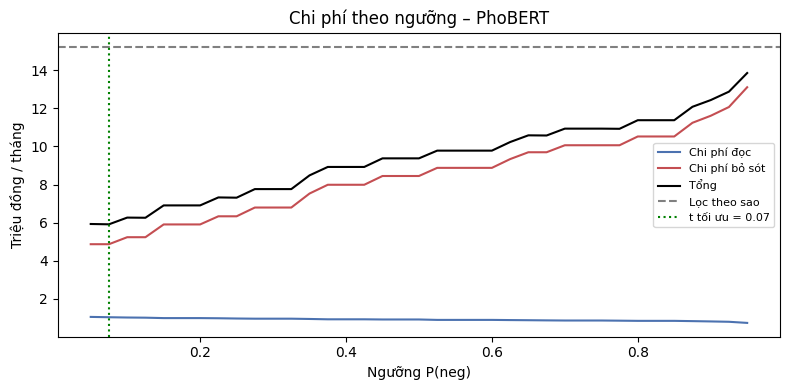

t                                 0.08
Số review phải đọc/tháng       1043.12
Bỏ sót review chê/tháng          97.45
Recall neg                        0.90
Chi phí đọc                 1043118.30
Chi phí bỏ sót              4872272.06
Tổng                        5915390.36
Name: 1, dtype: float64


In [10]:
ts = np.linspace(0.05, 0.95, 37)
sweep = []
for t in ts:
    c = strategy_cost(scores[BEST_P][:, 0] >= t)
    sweep.append({"t": t, **c, "Tổng": c["Chi phí đọc"] + c["Chi phí bỏ sót"]})
sweep = pd.DataFrame(sweep)
t_best = sweep.loc[sweep["Tổng"].idxmin(), "t"]
fig, ax = plt.subplots(figsize=(8, 4))
for col, c in [("Chi phí đọc", "#4C72B0"), ("Chi phí bỏ sót", "#C44E52"), ("Tổng", "black")]:
    ax.plot(sweep.t, sweep[col] / 1e6, label=col, color=c)
ax.axhline(cost.loc["(b) Lọc theo sao (1–2 sao)", "Tổng chi phí/tháng"] / 1e6, ls="--", color="gray", label="Lọc theo sao")
ax.axvline(t_best, ls=":", color="green", label=f"t tối ưu = {t_best:.2f}")
ax.set(xlabel="Ngưỡng P(neg)", ylabel="Triệu đồng / tháng", title=f"Chi phí theo ngưỡng – {BEST_P}")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{FIG}/cost_threshold.png", bbox_inches="tight"); plt.show()
print(sweep.loc[sweep["Tổng"].idxmin()].round(2))

### ROI 12 tháng của chiến lược ghép (d)

`ROI = (Tiết kiệm 12 tháng − Chi phí đầu tư) / Chi phí đầu tư`, trong đó Chi phí đầu tư = triển khai + 12 × vận hành.

So với **hai mốc**, vì kết luận phụ thuộc vào việc shop đang làm gì: lọc 1–2 sao, hoặc đọc tay toàn bộ.


In [11]:
def roi(c_miss, n, base_name, a=ASSUME):
    a = {**a, "C_MISS": c_miss, "N_review_thang": n}
    base = strategy_cost(strategies[base_name], a)
    mod = strategy_cost(strategies[GHEP], a)
    save = 12 * ((base["Chi phí đọc"] + base["Chi phí bỏ sót"]) - (mod["Chi phí đọc"] + mod["Chi phí bỏ sót"]))
    invest = a["CHI_PHI_TRIEN_KHAI"] + 12 * a["CHI_PHI_VAN_HANH_THANG"]
    return (save - invest) / invest

def bang_roi(base_name):
    return pd.DataFrame({f"C_MISS={cm//1000}k": {f"N={n}": roi(cm, n, base_name) for n in [1000, 3000, 10000]}
                         for cm in [25_000, 50_000, 100_000]})

sens, sens_doc = bang_roi(SAO_12), bang_roi(DOC_HET)
sens.to_csv(f"{REP}/roi_sensitivity.csv", encoding="utf-8-sig")
sens_doc.to_csv(f"{REP}/roi_sensitivity_doc_tay.csv", encoding="utf-8-sig")
print(f"ROI 12 tháng (giả định gốc) so với lọc 1–2 sao: {sens.loc['N=3000', 'C_MISS=50k']:.0%}")
print(f"ROI 12 tháng (giả định gốc) so với đọc tay toàn bộ: {sens_doc.loc['N=3000', 'C_MISS=50k']:.0%}")
print("Độ nhạy ROI so với lọc 1–2 sao (hàng: số review/tháng, cột: thiệt hại khi bỏ sót):")
display(sens.style.format("{:.0%}"))
print("Độ nhạy ROI so với đọc tay toàn bộ:")
display(sens_doc.style.format("{:.0%}"))


ROI 12 tháng (giả định gốc) so với lọc 1–2 sao: 562%
ROI 12 tháng (giả định gốc) so với đọc tay toàn bộ: -137%
Độ nhạy ROI so với lọc 1–2 sao (hàng: số review/tháng, cột: thiệt hại khi bỏ sót):


,C_MISS=25k,C_MISS=50k,C_MISS=100k
N=1000,6%,121%,351%
N=3000,217%,562%,1253%
N=10000,955%,2107%,4410%


Độ nhạy ROI so với đọc tay toàn bộ:


,C_MISS=25k,C_MISS=50k,C_MISS=100k
N=1000,-89%,-112%,-159%
N=3000,-67%,-137%,-276%
N=10000,9%,-223%,-687%


**Nhận xét.** Mô phỏng trong notebook 09 giả định 3.000 review/tháng, chi phí đọc 1.000 đồng/review, thiệt hại kỳ vọng 50.000 đồng/lời chê bỏ sót, đầu tư ban đầu 15 triệu đồng và vận hành 500.000 đồng/tháng. Chi phí đọc tương ứng 30 giây với mức lao động 120.000 đồng/giờ; thiệt hại bỏ sót giả định bằng xác suất mất khách 20% nhân lợi nhuận 250.000 đồng/khách. Các giả định này chưa được đo tại doanh nghiệp.

Chi phí sàng lọc mỗi tháng bằng số review cần đọc nhân chi phí đọc, cộng số lời chê bỏ sót nhân thiệt hại kỳ vọng. ROI 12 tháng bằng (tiết kiệm trong 12 tháng trừ đầu tư) chia đầu tư; đầu tư gồm triển khai và vận hành. Tập vàng lấy dư review ít sao nên notebook dùng trọng số đưa phân bố sao về tập Shopee đã làm sạch. Hiệu chỉnh này không bảo đảm đại diện cho các cửa hàng khác.

Theo bảng chi phí, chiến lược ghép “≤ 3 sao hoặc PhoBERT không dự đoán tích cực” cần đọc khoảng 1.210 review/tháng, bỏ sót khoảng 49 lời chê, tổng chi phí khoảng 3,65 triệu đồng/tháng. Recall tiêu cực sau hiệu chỉnh là 0,949; đây là Recall của chiến lược ghép, không phải riêng PhoBERT. PhoBERT có Recall tiêu cực 0,851 và F1-macro 0,704 trên tập vàng chưa hiệu chỉnh. So với lọc 1–2 sao, chiến lược ghép giảm chi phí mô phỏng từ 15,23 xuống 3,65 triệu đồng/tháng; ROI 12 tháng khoảng 562%.

Tuy nhiên, đọc tay toàn bộ được giả định không bỏ sót và chỉ tốn 3 triệu đồng/tháng. So với mốc này, chiến lược ghép có ROI khoảng −137%, nghĩa là lợi ích không bù đầu tư và phần chi phí tăng thêm. Với 1.000 review/tháng và thiệt hại bỏ sót 25.000 đồng, ROI so với lọc 1–2 sao chỉ khoảng 6%. Chỉ một kịch bản trong bảng so với đọc tay có ROI dương: 10.000 review/tháng và thiệt hại 25.000 đồng, khoảng 9%. Không thể kết luận AI luôn rẻ hơn đọc tay.

Các so sánh dùng tập vàng đã xem và mô hình phục vụ minh họa, nên chỉ có giá trị thăm dò. Trước khi đầu tư, cần đo thời gian đọc, tỷ lệ bỏ sót thật của nhân viên và thiệt hại thực tế, rồi kiểm tra chiến lược trên dữ liệu mới.

## 4. Human-in-the-loop

Câu có xác suất cao nhất < τ thì chuyển cho nhân viên xem lại. Đánh đổi: bao nhiêu % câu phải xem tay, đổi lại F1 trên phần máy tự xử lý tăng bao nhiêu?

In [12]:
P = scores[BEST_P]
conf = P.max(1)
pred = np.array(LABELS)[P.argmax(1)]
hitl = []
for tau in [0.0, 0.5, 0.6, 0.7, 0.8]:
    auto = conf >= tau
    hitl.append({"τ": tau, "% chuyển người": 1 - auto.mean(),
                 "F1-macro phần tự động": f1_score(gold.label[auto], pred[auto], average="macro") if auto.sum() else np.nan,
                 "Recall neg phần tự động": recall_score(gold.label[auto], pred[auto], labels=["neg"], average="macro") if auto.sum() else np.nan})
hitl = pd.DataFrame(hitl).round(3)
hitl.to_csv(f"{REP}/hitl.csv", index=False)
hitl

,τ,% chuyển người,F1-macro phần tự động,Recall neg phần tự động
0,0.0,0.000,0.704,0.851
1,0.5,0.013,0.700,0.864
2,0.6,0.023,0.707,0.871
3,0.7,0.047,0.702,0.875
4,0.8,0.073,0.722,0.907


## 5. Fairness: mô hình có bất lợi cho nhóm nào không?

In [13]:
fair = (gold.assign(pred=pred)
        .groupby("category")
        .apply(lambda d: pd.Series({"n": len(d), "% neg thật": (d.label == "neg").mean(),
                                    "F1-macro": f1_score(d.label, d.pred, average="macro"),
                                    "Recall neg": recall_score(d.label, d.pred, labels=["neg"], average="macro", zero_division=0)}),
               include_groups=False)
        .sort_values("F1-macro"))
fair.to_csv(f"{REP}/fairness_category.csv", encoding="utf-8-sig")
fair.round(3)

,n,% neg thật,F1-macro,Recall neg
category,,,,
Phụ kiện xe,33.0,0.606,0.588,0.850
Mẹ & bé,31.0,0.323,0.609,0.900
Thời trang,99.0,0.414,0.655,0.829
Mỹ phẩm,80.0,0.288,0.739,0.826
Đồ ăn,25.0,0.520,0.753,0.769
Điện tử,26.0,0.538,0.804,1.000
Sách – văn phòng phẩm,6.0,0.000,1.000,0.000


In [14]:
if os.path.exists(f"{REP}/unaccent_results.csv"):
    print("Văn bản không dấu (từ notebook 07):")
    display(pd.read_csv(f"{REP}/unaccent_results.csv"))

Văn bản không dấu (từ notebook 07):


,Train,ViSD test có dấu,ViSD test không dấu,Vàng có dấu,Vàng không dấu
0,A+B,0.717,0.470,0.619,0.445
1,A+B+Aug,0.719,0.465,0.629,0.537


**Nhận xét.** Trên vàng, PhoBERT có F1-macro 0,588 và Recall tiêu cực 0,850 ở Phụ kiện xe (33 câu), so với 0,804 và 1,000 ở Điện tử (26 câu). Cỡ mẫu nhỏ và cơ cấu nhãn khác nhau nên chưa chứng minh công bằng/bất công với nhóm người. Sách–văn phòng phẩm chỉ có 6 câu, không có nhãn tiêu cực: Recall ghi 0 theo quy ước zero_division, không phải bỏ sót toàn bộ lời chê. Ngành không có trong mẫu cũng chưa được đánh giá.

HITL chuyển câu có xác suất cao nhất dưới ngưỡng cho nhân viên. Mức minh họa 0,8 trong bảng HITL chuyển 7,3% câu; phần tự động có F1-macro 0,722, Recall tiêu cực 0,907. Đây là chỉ số trên phần giữ lại, không phải toàn hệ thống hoặc chất lượng xử lý của nhân viên. Chưa kiểm định hiệu chỉnh xác suất/ngưỡng độc lập. Câu tự tin cao vẫn có thể sai nên cần lấy mẫu kiểm tra cả nhóm này, ưu tiên phản ánh chất lượng/an toàn và nhiều khía cạnh trái chiều.

## 6. XAI: giá trị SHAP của TF-IDF + Logistic Regression

Với mô hình tuyến tính, SHAP có công thức chính xác (đúng với `shap.LinearExplainer`):

φ(từ j, lớp c) = w[c, j] × (x_j − E[x_j])

- `w`: hệ số của LR.
- `x_j`: giá trị TF-IDF của từ j trong câu.
- `E[x_j]`: trung bình trên tập train.

φ > 0 nghĩa là từ đó đẩy dự đoán **về phía** lớp c. Tổng φ cộng giá trị gốc ra đúng logit của câu. Code dưới tự tính nên không cần cài thư viện `shap`. Nếu muốn vẽ bằng `shap`, xem ô cuối.

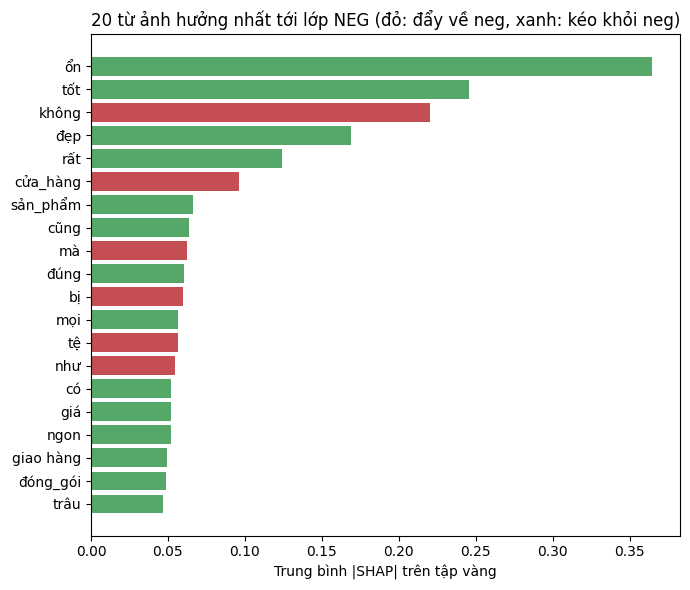

In [15]:
lr_pipe = fitted["TF-IDF+LR"]
ct, clf = lr_pipe.named_steps["vec"], lr_pipe.named_steps["clf"]
vocab = np.array([v.split("__", 1)[1] for v in ct.get_feature_names_out()])
S_ = load_sets()
X_train = ct.transform(pd.concat([S_["A"], S_["B"]])[["text_prep", "text_raw"]])
mu = np.asarray(X_train.mean(0)).ravel()
Xg_t = ct.transform(Xg)
k_neg = list(clf.classes_).index("neg")

def shap_linear(x_row, k):
    """SHAP của một câu (x_row: 1 dòng sparse)."""
    return (x_row.toarray().ravel() - mu) * clf.coef_[k]

def mean_abs_shap(X, k):
    """Trung bình |SHAP| mỗi từ trên cả tập, tính trên ma trận thưa (không đổi sang dense ~110 nghìn cột)."""
    X = X.tocsc()
    n, w = X.shape[0], np.abs(clf.coef_[k])
    nnz = np.diff(X.indptr)
    s = np.array([np.abs(X.data[X.indptr[j]:X.indptr[j + 1]] - mu[j]).sum() for j in range(X.shape[1])])
    return (s + (n - nnz) * mu) * w / n          # dòng không chứa từ j: |0 − mu_j| = mu_j

imp = pd.DataFrame({"từ": vocab, "mean|SHAP|": mean_abs_shap(Xg_t, k_neg), "hệ số neg": clf.coef_[k_neg]})
top = imp.sort_values("mean|SHAP|", ascending=False).head(20)[::-1]
plt.figure(figsize=(7, 6))
plt.barh(top["từ"], top["mean|SHAP|"], color=np.where(top["hệ số neg"] > 0, "#C44E52", "#55A868"))
plt.title("20 từ ảnh hưởng nhất tới lớp NEG (đỏ: đẩy về neg, xanh: kéo khỏi neg)")
plt.xlabel("Trung bình |SHAP| trên tập vàng")
plt.tight_layout(); plt.savefig(f"{FIG}/shap_global_neg.png", bbox_inches="tight"); plt.show()

**Nhận xét.** Ở hình tổng thể, “không”, “tệ”, “bị” có hệ số hướng về tiêu cực; “ổn”, “tốt”, “đẹp” hướng ngược lại. Điều này phù hợp tín hiệu thường gặp nhưng có ngoại lệ như “không tệ”. Hình tổng thể dùng trung bình trị tuyệt đối đóng góp, còn màu theo hệ số; màu không mô tả dấu đóng góp của mọi câu.

Giải thích từng câu cần so với nền trung bình train: từ không xuất hiện vẫn có đóng góp khác không vì TF-IDF thấp hơn nền. Cột đỏ mang tên từ khen không có nghĩa từ ấy luôn làm câu tiêu cực. SHAP giải thích cách LR dùng đặc trưng, không xác nhận lời khách nói hoặc chứng minh nhân quả. Từ chỉ sản phẩm có thể thành lối tắt nếu đi cùng một nhãn trong train; chia theo sản phẩm và xem lỗi sản phẩm mới giúp nhận diện rủi ro.

Dashboard dùng tích hệ số với TF-IDF để phản hồi nhanh, chưa trừ nền trung bình như notebook; cần gọi là đóng góp tuyến tính. Nhân viên nên xem đóng góp cùng review gốc, khía cạnh và mức chắc chắn thay vì dựa riêng một từ.

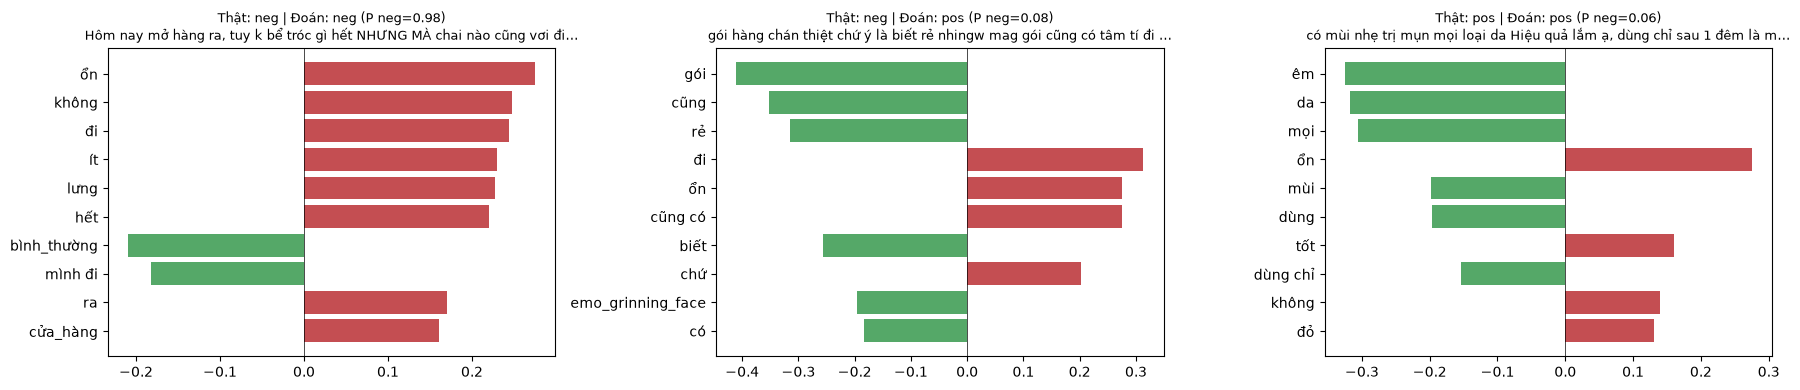

In [16]:
def explain(i, k=k_neg, top=10, ax=None):
    p = shap_linear(Xg_t[i], k)
    nz = np.argsort(np.abs(p))[::-1][:top]
    nz = nz[np.abs(p[nz]) > 0][::-1]
    ax = ax or plt.gca()
    ax.barh(vocab[nz], p[nz], color=np.where(p[nz] > 0, "#C44E52", "#55A868"))
    txt = gold.text_raw.iloc[i]
    ax.set_title(f"Thật: {gold.label.iloc[i]} | Đoán: {pred_lr[i]} (P neg={scores['TF-IDF+LR'][i, 0]:.2f})\n"
                 f"{txt[:70]}{'…' if len(txt) > 70 else ''}", fontsize=9)
    ax.axvline(0, color="k", lw=0.5)

pred_lr = np.array(LABELS)[scores["TF-IDF+LR"].argmax(1)]
ok = np.where((pred_lr == gold.label.values) & (gold.label.values == "neg"))[0]
wrong = np.where((pred_lr != gold.label.values) & (gold.label.values == "neg"))[0]
negation = np.where(gold.text_prep.str.contains(r"\bkhông\b").values & (gold.label.values != "neg"))[0]
picks = [x[0] for x in (ok, wrong, negation) if len(x)]
fig, axes = plt.subplots(1, len(picks), figsize=(6 * len(picks), 4))
for a, i in zip(np.atleast_1d(axes), picks):
    explain(i, ax=a)
plt.tight_layout(); plt.savefig(f"{FIG}/shap_local.png", bbox_inches="tight"); plt.show()

Ba ví dụ lần lượt là: một câu chê **đoán đúng**, một câu chê **bị bỏ sót**, và một câu có "không" nhưng **không phải lời chê**. Hãy đổi chỉ số trong `picks` để chọn ví dụ dễ giải thích hơn cho báo cáo.

In [17]:
# (Tùy chọn) Vẽ bằng thư viện shap: pip install shap
try:
    import shap
    expl = shap.LinearExplainer(clf, X_train, feature_names=vocab)
    sv = expl(Xg_t)
    shap.plots.beeswarm(sv[:, :, k_neg], max_display=15, show=False)
    plt.savefig(f"{FIG}/shap_beeswarm_neg.png", bbox_inches="tight"); plt.show()
except ImportError:
    print("Chưa cài shap, bỏ qua (đã có hình tự tính ở trên).")

Chưa cài shap, bỏ qua (đã có hình tự tính ở trên).


## 7. Xuất câu sai để phân tích lỗi

Đã phân nhóm 40 dòng trong `report/error_analysis.csv` theo nội dung, Codex đề xuất ngày 08/11/2026. Đây là thăm dò cần người thực hiện duyệt; giữ nguyên nhãn/dự đoán. Tổng hợp ở `report/error_group_summary.csv`. Nhãn nghi ngờ được đánh dấu, không tự sửa vàng/tính lại điểm.

In [18]:
err = gold.assign(pred=pred, p_max=conf.round(2))[pred != gold.label.values]
err = err[["id", "category", "rating", "label", "pred", "p_max", "text_raw"]].sample(min(40, len(err)), random_state=42)
err["nhom_loi"] = ""
out = f"{REP}/error_analysis.csv"
if os.path.exists(out) and pd.read_csv(out).nhom_loi.notna().any():
    print("Đã có file phân tích lỗi bạn đang điền, không ghi đè.")
else:
    err.to_csv(out, index=False, encoding="utf-8-sig")
print(len(err), "câu sai đã xuất")
err.head(10)

40 câu sai đã xuất


,id,category,rating,label,pred,p_max,text_raw,nhom_loi
75,shp_1413,Thời trang,4,neg,pos,0.98,đúng đúng đúng Khó chỉnh giờ,
264,shp_1046,Thời trang,2,neg,neu,0.40,vai da co Lần đầu mua ok xong đặt tiếp ai dè c...,
292,shp_0197,Thời trang,4,pos,neg,0.99,tốt Sao tôi mua 5 nhưng nhận hàng có 3. Shop đ...,
262,shp_2410,Mỹ phẩm,5,neu,pos,0.98,đóng gói rất cần thận,
98,shp_1021,Thời trang,4,pos,neu,0.71,mềm mại nu giống hình Áo mặc size vừa với mình...,
170,shp_0464,Phụ kiện xe,2,neg,neu,0.76,ddungs đen ko bt Hàng dùng tốt nhưng mình nhận...,
168,shp_1027,Thời trang,4,neg,neu,0.74,da Dán xoài hơi mỏng và k có đệm làm cho ngực ...,
163,shp_0456,Phụ kiện xe,3,neg,neu,0.63,Mua lần 2 nhưng lần này mình không ưng ý lắm. ...,
178,shp_1047,Thời trang,2,neg,pos,0.41,"siêu cứng, mình đã mua 3cái mà kh nhớ shop nào...",
117,shp_1013,Thời trang,4,neu,pos,0.98,"Đúng mô tả Da Giao hàng nhanh, shop có che tên...",
